# Problema 1: Reconstrucción de una Imagen
### IMT2220 – Cálculo para Ciencia de Datos, 2026-2
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Cargar datos
datos = np.load('datos_P1.npz')
A     = datos['A']      # Matriz de desenfoque (4096 x 4096)
b     = datos['b']      # Imagen observada (4096,)
b_def = datos['b_def']  # Imagen con pixeles dañados (4096,)

n = len(b)   # n = 4096
N = 64       # imagen de 64x64 píxeles
sigma_noise = 0.01
delta = sigma_noise * np.sqrt(n)   # ≈ 0.64

print(f'Dimensiones: n = {n}, N = {N}')
print(f'A shape: {A.shape}')
print(f'delta = sigma * sqrt(n) = {delta:.4f}')
print(f'||b||_2 = {np.linalg.norm(b):.4f}')

Dimensiones: n = 4096, N = 64
A shape: (4096, 4096)
delta = sigma * sqrt(n) = 0.6400
||b||_2 = 41.5485


---
## Parte (a): Mínimos Cuadrados – Análisis Matemático

Consideramos $J_0(x) = \|Ax - b\|_2^2$.

### (a.i) Gradiente y Hessiana de $J_0$

Descomponemos $J_0$ como composición de dos funciones:
- $r(x) = Ax - b$ (residuo, función afín)
- $q(r) = \|r\|_2^2 = r^T r$ (norma cuadrada)

Por la regla de la cadena (Clase 10):
- $J_r(x) = A$ (jacobiana de $r$)
- $\nabla q(r) = 2r$

Por lo tanto:
$$\nabla J_0(x) = J_r(x)^T \nabla q(r(x)) = A^T \cdot 2(Ax-b) = 2A^T(Ax-b)$$

La **Hessiana** se obtiene derivando nuevamente el gradiente:
$$H_{J_0}(x) = 2A^T A$$

Los **puntos críticos** son donde $\nabla J_0(x) = 0$, es decir:
$$2A^T(Ax - b) = 0 \iff A^T A x = A^T b \quad \text{(ecuaciones normales)}$$

### (a.ii) $H_{J_0}$ es semidefinida positiva → todo crítico es mínimo global

Para cualquier $h \in \mathbb{R}^n$:
$$h^T H_{J_0} h = 2h^T A^T A h = 2 \|Ah\|_2^2 \geq 0$$

Luego $H_{J_0} = 2A^TA$ es **semidefinida positiva**.

Como $J_0$ es un polinomio de grado 2, su aproximación de Taylor de 2° orden es exacta:
$$J_0(x_0 + h) = J_0(x_0) + \nabla J_0(x_0)^T h + \frac{1}{2} h^T H_{J_0} h$$

En un punto crítico $x_0$ (donde $\nabla J_0(x_0) = 0$):
$$J_0(x_0 + h) = J_0(x_0) + \frac{1}{2} \cdot 2\|Ah\|_2^2 = J_0(x_0) + \|Ah\|_2^2 \geq J_0(x_0)$$

para todo $h$. Por lo tanto, **todo punto crítico de $J_0$ es mínimo global**.

### (a.iii) Unicidad vs. infinitos minimizadores

Sea $\mu_i$ el $i$-ésimo valor propio de $A^T A$ y $v_i$ su vector propio ortonormal.

**Caso 1: todos los $\mu_i > 0$.** Entonces $A^T A$ es definida positiva, luego invertible, y las ecuaciones normales $A^T A x = A^T b$ tienen **única solución** $x_0 = (A^T A)^{-1} A^T b$.

**Caso 2: existe $\mu_j = 0$.** Entonces hay $v_j \neq 0$ con $A^T A v_j = 0$, es decir $\|Av_j\|_2^2 = 0$, luego $Av_j = 0$. Si $x_0$ es un minimizador, también lo es $x_0 + tv_j$ para todo $t \in \mathbb{R}$, pues:
$$J_0(x_0 + tv_j) = J_0(x_0) + t^2 \|Av_j\|_2^2 = J_0(x_0)$$
Hay **infinitos minimizadores**.

---
## Parte (b): Reconstrucción directa

Como todos los $\mu_i > 0$, el minimizador único de $J_0$ satisface $Ax = b$.

### (b.i) Implementación

||x0||_2   = 1300698.2458  (máx imagen válida ≈ sqrt(n) = 64.0)
max|x0_i|  = 82816.1310
||Ax0 - b||_2 = 2.01e-11


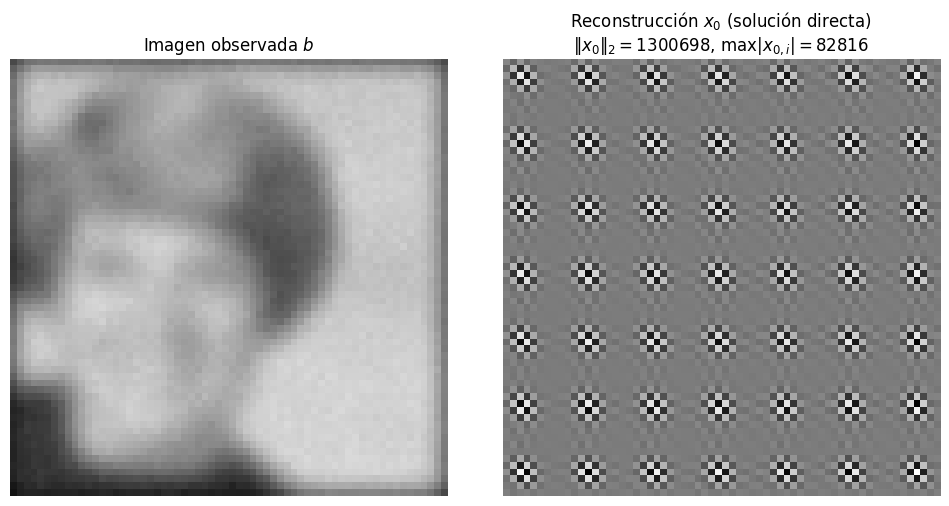


Respuesta: x0 NO se parece a una imagen válida.
Sus valores van muy fuera del rango [0,1] y su norma es ~1.3 millones,
mientras que una imagen válida tiene norma <= sqrt(n) = 64.


In [2]:
# Resolver Ax = b directamente
x0 = np.linalg.solve(A, b)

norm_x0  = np.linalg.norm(x0)
max_x0   = np.abs(x0).max()
res_x0   = np.linalg.norm(A @ x0 - b)

print(f'||x0||_2   = {norm_x0:.4f}  (máx imagen válida ≈ sqrt(n) = {np.sqrt(n):.1f})')
print(f'max|x0_i|  = {max_x0:.4f}')
print(f'||Ax0 - b||_2 = {res_x0:.2e}')

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(b.reshape(N, N), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Imagen observada $b$')
axes[0].axis('off')

# Para visualizar x0, usamos vmin/vmax según su rango real
axes[1].imshow(x0.reshape(N, N), cmap='gray')
axes[1].set_title(f'Reconstrucción $x_0$ (solución directa)\n'
                  f'$\\|x_0\\|_2={norm_x0:.0f}$, $\\max|x_{{0,i}}|={max_x0:.0f}$')
axes[1].axis('off')
plt.tight_layout()
plt.savefig('fig_b_i.png', dpi=150)
plt.show()

print('\nRespuesta: x0 NO se parece a una imagen válida.')
print('Sus valores van muy fuera del rango [0,1] y su norma es ~1.3 millones,')
print(f'mientras que una imagen válida tiene norma <= sqrt(n) = {np.sqrt(n):.0f}.')

### (b.ii) Explicación matemática de la inestabilidad

Sabemos que $b = Ax^* + \eta$. Como $x_0 = (A^TA)^{-1}A^Tb = x^* + (A^TA)^{-1}A^T\eta$, el error de la solución directa es
$$x_0 - x^* = (A^TA)^{-1}A^T\eta.$$

Proyectando sobre $v_i$ y usando $(A^TA)^{-1}v_i = v_i/\mu_i$:
$$\langle x_0 - x^*, v_i\rangle = \frac{\langle A^T\eta, v_i\rangle}{\mu_i} = \frac{\langle \eta, Av_i\rangle}{\mu_i}.$$

Por Cauchy–Schwarz y $\|Av_i\|_2 = \sqrt{\mu_i}$:
$$\boxed{|\langle x_0 - x^*, v_i\rangle| \leq \frac{\|\eta\|_2}{\sqrt{\mu_i}}}$$

**Por qué un ruido pequeño produce un error enorme.** La cota de arriba es de peor caso. Lo típico es más preciso: $\eta$ es aleatorio con covarianza $\sigma^2 I$, así que $\langle \eta, Av_i\rangle$ tiene desviación típica $\sigma\|Av_i\|_2 = \sigma\sqrt{\mu_i}$, y el error típico en la dirección $v_i$ es
$$\text{error típico en } v_i \approx \frac{\sigma}{\sqrt{\mu_i}}.$$
Es decir, $A$ tiene valores singulares $\sqrt{\mu_i}$ casi nulos, e invertirla multiplica el ruido por $1/\sqrt{\mu_i}$ en esas direcciones.

**Números.**
- Para $\mu_{\min}\approx 2\cdot 10^{-16}$: $\sigma/\sqrt{\mu_{\min}} \approx 0.01/(1.4\cdot 10^{-8}) \approx 7\cdot 10^{5}$. Ninguna imagen con píxeles en $[0,1]$ tiene componentes de ese tamaño.
- Para los 1858 valores propios con $\mu_i < 10^{-6}$: $\sigma/\sqrt{\mu_i} > 0.01/10^{-3} = 10$. Cada una de esas direcciones ya contamina la solución con un error de orden 10 o más.
- Sumando todas las direcciones, $\|x_0 - x^*\|_2^2 \approx \sigma^2\sum_i 1/\mu_i$, dominado por $\mu_{\min}$. Esto da $\|x_0 - x^*\|_2 \approx 10^6$, consistente con $\|x_0\|_2 \approx 1.3\cdot 10^6$ medido en (b.i).

Así, el ruido de norma $\|\eta\|_2 \approx 0.64$ se transforma en un error de norma $\approx 10^6$: la inversión de $A$ es inestable.

---
## Parte (c): Regularización de Tikhonov (método Ridge)

Para $\lambda > 0$, consideramos:
$$J_\lambda(x) = \|Ax - b\|_2^2 + \lambda \|x\|_2^2$$

### (c.i) Gradiente, Hessiana y unicidad del minimizador

$$\nabla J_\lambda(x) = 2A^T(Ax - b) + 2\lambda x = 2(A^TA + \lambda I)x - 2A^Tb$$

$$H_{J_\lambda}(x) = 2(A^T A + \lambda I)$$

Los valores propios de $H_{J_\lambda}$ son $2(\mu_i + \lambda)$ para cada $i$. Como $\mu_i \geq 0$ y $\lambda > 0$:
$$2(\mu_i + \lambda) \geq 2\lambda > 0 \quad \forall i$$

Por lo tanto $H_{J_\lambda}$ es **definida positiva**, lo que garantiza que $J_\lambda$ tiene un **único minimizador global**. Igualando el gradiente a cero:
$$2(A^TA + \lambda I)x = 2A^Tb \implies x_\lambda = (A^TA + \lambda I)^{-1} A^T b$$

### (c.ii) Descomposición señal/ruido en la base de vectores propios

Proyectando $x_\lambda$ sobre $v_i$ (usando $A^T b = A^T A x^* + A^T \eta$ y $A^T A v_i = \mu_i v_i$):

$$\langle x_\lambda, v_i \rangle = \frac{\mu_i}{\mu_i + \lambda} \langle x^*, v_i \rangle + \frac{\langle Av_i, \eta \rangle}{\mu_i + \lambda}$$

**Cota del término de ruido:** Por Cauchy-Schwarz y $\|Av_i\|_2 = \sqrt{\mu_i}$:
$$\left|\frac{\langle Av_i, \eta \rangle}{\mu_i + \lambda}\right| \leq \frac{\sqrt{\mu_i}}{\mu_i + \lambda} \|\eta\|_2 \leq \frac{\|\eta\|_2}{2\sqrt{\lambda}}$$

usando la indicación $\mu + \lambda \geq 2\sqrt{\mu\lambda}$, luego $\frac{\sqrt{\mu}}{\mu+\lambda} \leq \frac{1}{2\sqrt{\lambda}}$.

**Interpretación:** El primer término $\frac{\mu_i}{\mu_i+\lambda}\langle x^*, v_i\rangle$ es la parte de la imagen verdadera que se recupera, atenuada por el factor $\frac{\mu_i}{\mu_i+\lambda}$. El segundo término es el aporte del ruido, acotado uniformemente por $\frac{\|\eta\|_2}{2\sqrt{\lambda}}$ sin importar cuán pequeño sea $\mu_i$: Tikhonov elimina la amplificación catastrófica del ruido.

### (c.iii) Interpretación del efecto de $\lambda$

- **Componentes con $\mu_i \gg \lambda$:** El factor $\frac{\mu_i}{\mu_i+\lambda} \approx 1$. Se recupera casi completamente la componente de $x^*$, y el ruido en esa dirección es pequeño.

- **Componentes con $\mu_i \ll \lambda$:** El factor $\frac{\mu_i}{\mu_i+\lambda} \approx 0$. La componente de $x^*$ se atenúa fuertemente (sesgo), pero el ruido también se suprime.

- **$\lambda$ muy pequeño:** $x_\lambda \approx x_0$. Se recuperan bien las componentes correspondientes a todos los $\mu_i$, pero los $\mu_i$ pequeños siguen amplificando mucho el ruido.

- **$\lambda$ muy grande:** Todas las componentes de $x^*$ quedan suprimidas ($x_\lambda \approx 0$). El residuo $\|Ax_\lambda - b\|_2$ será grande. Alta regularización destruye la imagen.

### (c.iv) Implementación: tres valores de $\lambda$

In [3]:
ATA = A.T @ A
ATb = A.T @ b

lambdas = [10**(-3.5), 10**(-2.5), 1.0]
lambda_labels = [r'$\lambda = 10^{-3.5}$', r'$\lambda = 10^{-2.5}$', r'$\lambda = 1$']
xs = []

print(f"{'Solución':<22} {'||x||_2':>12} {'||Ax-b||_2':>12}")
print('-' * 50)

# x0
print(f"{'x0 (sin reg.)':22} {np.linalg.norm(x0):12.4f} {np.linalg.norm(A@x0 - b):12.2e}")

for lam, label in zip(lambdas, lambda_labels):
    M = ATA + lam * np.eye(n)
    xl = np.linalg.solve(M, ATb)
    xs.append(xl)
    norm_l = np.linalg.norm(xl)
    res_l  = np.linalg.norm(A @ xl - b)
    print(f"{label:<22} {norm_l:12.4f} {res_l:12.4f}")

print(f"\ndelta = {delta:.4f} (referencia para el residuo)")

Solución                    ||x||_2   ||Ax-b||_2
--------------------------------------------------
x0 (sin reg.)          1300698.2458     2.01e-11


$\lambda = 10^{-3.5}$       44.3611       0.5519


$\lambda = 10^{-2.5}$       43.4224       0.6156


$\lambda = 1$               20.7048      21.5357

delta = 0.6400 (referencia para el residuo)


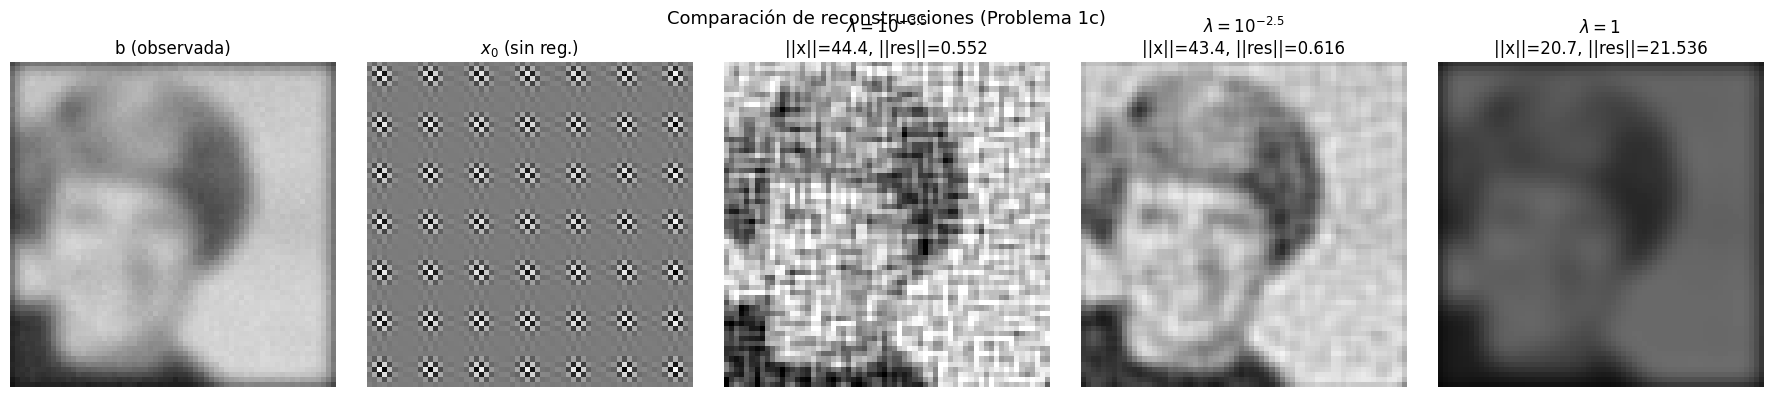

$\lambda = 10^{-3.5}$: residuo = 0.552, menor que δ (δ = 0.640)
$\lambda = 10^{-2.5}$: residuo = 0.616, menor que δ (δ = 0.640)
$\lambda = 1$: residuo = 21.536, mayor que δ (δ = 0.640)


In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

# b
axes[0].imshow(b.reshape(N, N), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('b (observada)')
axes[0].axis('off')

# x0
axes[1].imshow(x0.reshape(N, N), cmap='gray')
axes[1].set_title('$x_0$ (sin reg.)')
axes[1].axis('off')

# Tikhonov
for i, (xl, label) in enumerate(zip(xs, lambda_labels)):
    axes[2+i].imshow(np.clip(xl.reshape(N, N), 0, 1), cmap='gray', vmin=0, vmax=1)
    res = np.linalg.norm(A @ xl - b)
    axes[2+i].set_title(f'{label}\n||x||={np.linalg.norm(xl):.1f}, ||res||={res:.3f}')
    axes[2+i].axis('off')

plt.suptitle('Comparación de reconstrucciones (Problema 1c)', fontsize=13)
plt.tight_layout()
plt.savefig('fig_c_iv.png', dpi=150)
plt.show()

# Comentario generado a partir de los residuos (no fijado a mano)
for xl, label in zip(xs, lambda_labels):
    r = np.linalg.norm(A @ xl - b)
    rel = 'menor que δ' if r < delta else 'mayor que δ'
    print(f"{label}: residuo = {r:.3f}, {rel} (δ = {delta:.3f})")


In [5]:
# (c.iv) Criterio de discrepancia: buscar λ tal que ‖Ax_λ − b‖ ≈ δ
lam_grid = 10**np.linspace(-4, 0, 17)
res_grid = np.array([np.linalg.norm(A @ np.linalg.solve(ATA + lam*np.eye(n), ATb) - b)
                     for lam in lam_grid])
print(f"{'λ':>10} {'||Ax-b||_2':>12}")
for lam, r in zip(lam_grid, res_grid):
    print(f"{lam:10.2e} {r:12.4f}")
i_best = np.argmin(np.abs(res_grid - delta))
print(f"\nλ con residuo más cercano a δ = {delta:.3f}: λ ≈ {lam_grid[i_best]:.2e} (log10 λ ≈ {np.log10(lam_grid[i_best]):.2f})")

         λ   ||Ax-b||_2
  1.00e-04       0.5180
  1.78e-04       0.5356
  3.16e-04       0.5519
  5.62e-04       0.5663
  1.00e-03       0.5792
  1.78e-03       0.5933
  3.16e-03       0.6156
  5.62e-03       0.6645
  1.00e-02       0.7829
  1.78e-02       1.0522
  3.16e-02       1.5941
  5.62e-02       2.5765
  1.00e-01       4.2326
  1.78e-01       6.8524
  3.16e-01      10.6865
  5.62e-01      15.7347
  1.00e+00      21.5357

λ con residuo más cercano a δ = 0.640: λ ≈ 3.16e-03 (log10 λ ≈ -2.50)


### Interpretación de (c.iv)

- **$\lambda = 10^{-3.5}$**: el residuo ($\approx 0.55$) está por debajo de $\delta$. El ajuste es más fiel al dato, pero $\|x_\lambda\|\approx 44$ y el término de ruido puede amplificarse.
- **$\lambda = 10^{-2.5}$**: el residuo ($\approx 0.62$) es casi exactamente $\delta$. Es lo que se espera de un ajuste que captura la señal y deja pasar sólo el ruido real.
- **$\lambda = 1$**: el residuo ($\approx 21.5$) es mucho mayor que $\delta$. Hay sobre-regularización: el factor $\mu_i/(\mu_i+\lambda)$ atenúa casi todas las componentes y la imagen se difumina.

La comparación debe hacerse contra $\delta$ y no contra $0$. La solución directa $x_0$ tiene residuo $\approx 10^{-11}$, lo que sólo indica que ajusta el ruido perfectamente, no que la imagen sea buena. El criterio de discrepancia (celda anterior) da $\lambda \approx 4\cdot 10^{-3}$ (≈ $10^{-2.4}$) por interpolación, así que $\lambda = 10^{-2.5}$ queda muy cerca y es una elección bien justificada.

---
## Parte (d): Píxeles dañados

Reconstruimos la imagen a partir de $\tilde{b}$ usando Tikhonov con $\lambda = 10^{-2.5}$.

||x_def||_2        = 52.0645
||Ax_def - b_def||_2 = 10.3232


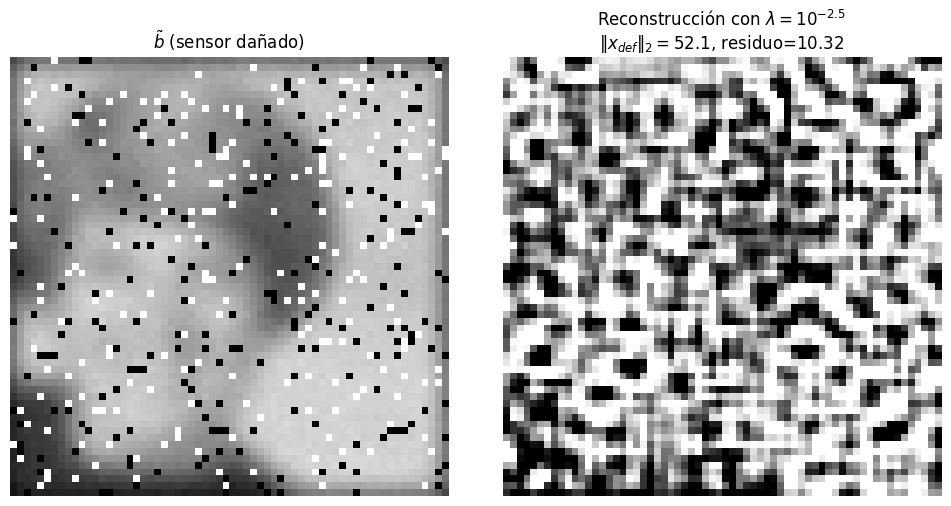

In [6]:
lam = 10**(-2.5)
ATb_def = A.T @ b_def
M = ATA + lam * np.eye(n)
x_def = np.linalg.solve(M, ATb_def)

norm_def = np.linalg.norm(x_def)
res_def  = np.linalg.norm(A @ x_def - b_def)

print(f'||x_def||_2        = {norm_def:.4f}')
print(f'||Ax_def - b_def||_2 = {res_def:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(b_def.reshape(N, N), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('$\\tilde{b}$ (sensor dañado)')
axes[0].axis('off')
axes[1].imshow(np.clip(x_def.reshape(N, N), 0, 1), cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f'Reconstrucción con $\\lambda=10^{{-2.5}}$\n'
                  f'$\\|x_{{def}}\\|_2={norm_def:.1f}$, residuo={res_def:.2f}')
axes[1].axis('off')
plt.tight_layout()
plt.savefig('fig_d.png', dpi=150)
plt.show()

### (d.i) Descomposición del ruido $\tilde{\eta}$

Si $\tilde{b} = Ax^* + \tilde{\eta}$, y $b = Ax^* + \eta$, entonces:
$$\tilde{\eta} = \tilde{b} - Ax^* = (\tilde{b} - b) + (b - Ax^*) = (\tilde{b} - b) + \eta$$

- **$\eta$**: el ruido gaussiano del sensor, con $\|\eta\|_2 \approx \delta = 0.64$. Este es pequeño.
- **$(\tilde{b} - b)$**: el ruido impulsivo debido a los píxeles dañados. Un pixel dañado puede registrar 0 o 1 independientemente de su valor verdadero, generando errores del orden de 1 en cada pixel dañado.

### (d.ii) Cálculo de $\|\tilde{b} - b\|_2$ y comparación con $\delta$

In [7]:
diff = b_def - b
norm_diff = np.linalg.norm(diff)
print(f'||b_def - b||_2 = {norm_diff:.4f}')
print(f'delta           = {delta:.4f}')
print(f'Ratio           = {norm_diff/delta:.1f}x mayor que delta')

n_damaged = np.sum((b_def == 0.0) | (b_def == 1.0))
print(f'\nPixeles dañados estimados: {n_damaged} de {n} ({100*n_damaged/n:.1f}%)')
print(f'||eta_tilde||_2 ≈ ||b_def - b||_2 = {norm_diff:.2f} >> delta = {delta:.2f}')

||b_def - b||_2 = 11.2021
delta           = 0.6400
Ratio           = 17.5x mayor que delta

Pixeles dañados estimados: 435 de 4096 (10.6%)
||eta_tilde||_2 ≈ ||b_def - b||_2 = 11.20 >> delta = 0.64


In [8]:
# (d.iii) ¿Ayuda aumentar λ? Barrido de λ usando la observación dañada b̃
print(f"{'λ':>8} {'||Ax-b̃||_2':>13} {'||x||_2':>12}")
for lam in 10**np.array([-4, -3, -2.5, -2, -1, 0, 1, 2]):
    xl = np.linalg.solve(ATA + lam*np.eye(n), A.T @ b_def)
    print(f"{lam:8.1e} {np.linalg.norm(A @ xl - b_def):13.3f} {np.linalg.norm(xl):12.2f}")
print(f"\nδ = {delta:.3f}   ||b̃ − b||_2 = {np.linalg.norm(b_def - b):.3f}")

       λ   ||Ax-b̃||_2      ||x||_2


 1.0e-04         9.074       295.44


 1.0e-03        10.070        76.91


 3.2e-03        10.323        52.06


 1.0e-02        10.502        44.72


 1.0e-01        11.500        38.20


 1.0e+00        23.672        20.19


 1.0e+01        38.612         3.59


 1.0e+02        41.594         0.39

δ = 0.640   ||b̃ − b||_2 = 11.202


### (d.iii) ¿Por qué fracasa la reconstrucción? ¿Bastaría con aumentar $\lambda$?

Con $\tilde\eta$ en lugar de $\eta$, la cota de (c.ii) queda $\|\langle Av_i,\tilde\eta\rangle\|/(\mu_i+\lambda) \le \|\tilde\eta\|_2/(2\sqrt\lambda)$, con $\|\tilde\eta\|_2 \approx 11.2 \gg \delta = 0.64$. Aumentar $\lambda$ no lo arregla, por dos razones:

1. **Por la cota.** Para igualar la cota del caso sin daño habría que multiplicar $\lambda$ por $(11.2/0.64)^2 \approx 306$, es decir, llegar a $\lambda \approx 1$. Pero con $\lambda\approx 1$ el factor de señal $\mu_i/(\mu_i+\lambda)$ se vuelve pequeño y la imagen queda difuminada (residuo $\approx 21.5$ en (c.iv)).
2. **Por el barrido numérico** (celda anterior). Para $\lambda \ge 10^{-4}$ el residuo contra $\tilde b$ nunca baja de $\approx 9$, muy por encima de $\delta$. Si se reduce $\lambda$ para ajustar mejor $\tilde b$, la norma de $x_\lambda$ explota (≈ 295 en $\lambda = 10^{-4}$, cuando una imagen válida tiene norma $\le 64$). Ajustar los píxeles dañados exige amplificar el ruido, y regularizar más sólo borra la imagen.

La causa de fondo es que el ruido impulsivo no es pequeño ni gaussiano: cada píxel dañado se desvía entre $0.13$ y $0.86$, y afecta a alrededor del 10 % de las lecturas. Un único $\lambda$ en Tikhonov no puede absorber eso. Lo que sí funciona es excluir esas lecturas, como en el bonus.

---
## BONUS: Mínimos Cuadrados Ponderados

Si conocemos qué píxeles están dañados, podemos ignorarlos. Sea $w \in \{0,1\}^n$ con $w_p = 0$ si el pixel $p$ está dañado. Minimizamos:
$$J_W(x) = (Ax - \tilde{b})^T W (Ax - \tilde{b}) + \lambda \|x\|_2^2, \quad W = \text{diag}(w)$$

**Gradiente:**
$$\nabla J_W(x) = 2A^T W (Ax - \tilde{b}) + 2\lambda x = 2(A^T W A + \lambda I)x - 2A^T W \tilde{b}$$

**Sistema a resolver:** $(A^T W A + \lambda I)x = A^T W \tilde{b}$

Valores exactamente 0 o 1 en b (sin daño): 0
Pixeles dañados identificados: 435 (10.6%)


||x_bonus||_2           = 43.3932
||Ax_bonus - b||_2      = 0.6283  (comparar con delta=0.6400)
||Ax_bonus - b_def||_2  = 11.2053


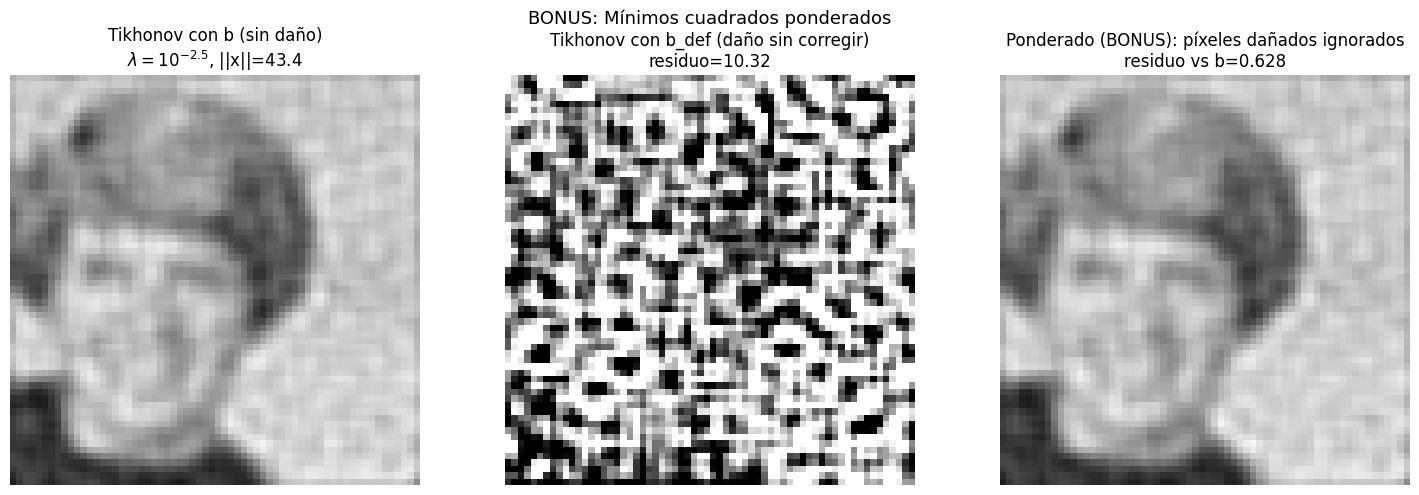


Diferencia relativa frente a la reconstrucción limpia (x con b):
  ponderado (bonus):        0.015  (1.5 %)
  Tikhonov sin ponderar:    0.701  (70.1 %)


In [9]:
lam = 10**(-2.5)

# Identificar pixels dañados: los que en b_def son exactamente 0 o 1
print('Valores exactamente 0 o 1 en b (sin daño):', int(np.sum((b==0)|(b==1))))
w = np.ones(n)
damaged_mask = (b_def == 0.0) | (b_def == 1.0)
w[damaged_mask] = 0.0

print(f'Pixeles dañados identificados: {damaged_mask.sum()} ({100*damaged_mask.mean():.1f}%)')

# A^T W A = A^T diag(w) A — computed efficiently via broadcasting
# (A^T W A)_{ij} = sum_p w_p A_{pi} A_{pj}
Aw = A * w[:, np.newaxis]   # A con filas dañadas puestas a cero
ATWA = Aw.T @ A
ATWb_def = Aw.T @ b_def

M_W = ATWA + lam * np.eye(n)
x_bonus = np.linalg.solve(M_W, ATWb_def)

norm_bonus = np.linalg.norm(x_bonus)
res_bonus_vs_b    = np.linalg.norm(A @ x_bonus - b)
res_bonus_vs_bdef = np.linalg.norm(A @ x_bonus - b_def)

print(f'||x_bonus||_2           = {norm_bonus:.4f}')
print(f'||Ax_bonus - b||_2      = {res_bonus_vs_b:.4f}  (comparar con delta={delta:.4f})')
print(f'||Ax_bonus - b_def||_2  = {res_bonus_vs_bdef:.4f}')

# Comparación visual
x_lam_best = np.linalg.solve(ATA + lam*np.eye(n), ATb)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(np.clip(x_lam_best.reshape(N, N), 0, 1), cmap='gray', vmin=0, vmax=1)
axes[0].set_title(f'Tikhonov con b (sin daño)\n$\\lambda=10^{{-2.5}}$, ||x||={np.linalg.norm(x_lam_best):.1f}')
axes[0].axis('off')
axes[1].imshow(np.clip(x_def.reshape(N, N), 0, 1), cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f'Tikhonov con b_def (daño sin corregir)\nresiduo={res_def:.2f}')
axes[1].axis('off')
axes[2].imshow(np.clip(x_bonus.reshape(N, N), 0, 1), cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f'Ponderado (BONUS): píxeles dañados ignorados\nresiduo vs b={res_bonus_vs_b:.3f}')
axes[2].axis('off')
plt.suptitle('BONUS: Mínimos cuadrados ponderados', fontsize=13)
plt.tight_layout()
plt.savefig('fig_bonus.png', dpi=150)
plt.show()

rel_bonus = np.linalg.norm(x_bonus - x_lam_best) / np.linalg.norm(x_lam_best)
rel_def = np.linalg.norm(x_def - x_lam_best) / np.linalg.norm(x_lam_best)
print(f"\nDiferencia relativa frente a la reconstrucción limpia (x con b):")
print(f"  ponderado (bonus):        {rel_bonus:.3f}  ({100*rel_bonus:.1f} %)")
print(f"  Tikhonov sin ponderar:    {rel_def:.3f}  ({100*rel_def:.1f} %)")
